In [1]:
import numpy as np
import matplotlib.pyplot as plt
import aurora
import pandas as pd 

In [2]:
sim_dir = r'C:\Users\elyse\Downloads\Python\PSFC\XRS_fitting\sim_data'
SOURCE = {'ioniz': -1, 'excit': 0, 'recom': 1, 'drsat': 1}  # charge state that drives each process
TYPES = {'ion': 'ioniz', 'exc': 'excit', 'rec': 'recom', 'drs': 'drsat'}

def load_pec(z):
    t = aurora.read_adf15(rf'{sim_dir}\pec#ca{z}.dat')
    t['type'] = t['type'].str.split().str[-1].str[:3].map(TYPES)
    t['z'] = z
    return t

def line_emissivity(t, ne_cm3, Te_eV, fz):
    pec = [10 ** f.ev(np.log10(ne_cm3), np.log10(Te_eV)).item() for f in t['log10 PEC fun']]
    source = t['z'] + t['type'].map(SOURCE)
    out = t[['z', 'isel', 'lambda [A]', 'type']].copy()
    out['emiss'] = np.array(pec) * ne_cm3 * fz[source.to_numpy()]
    return out

ne, Te = 1e14, 1000.0
atom = aurora.get_atom_data('Ca', ['scd', 'acd'])  # downloads automatically
_, fz = aurora.get_frac_abundances(atom, np.array([ne]), np.array([Te]), plot=False)

lines = pd.concat([line_emissivity(load_pec(z), ne, Te, fz[0]) for z in range(15, 20)],
                  ignore_index=True)
window = lines[lines['lambda [A]'].between(3.17, 3.22)]


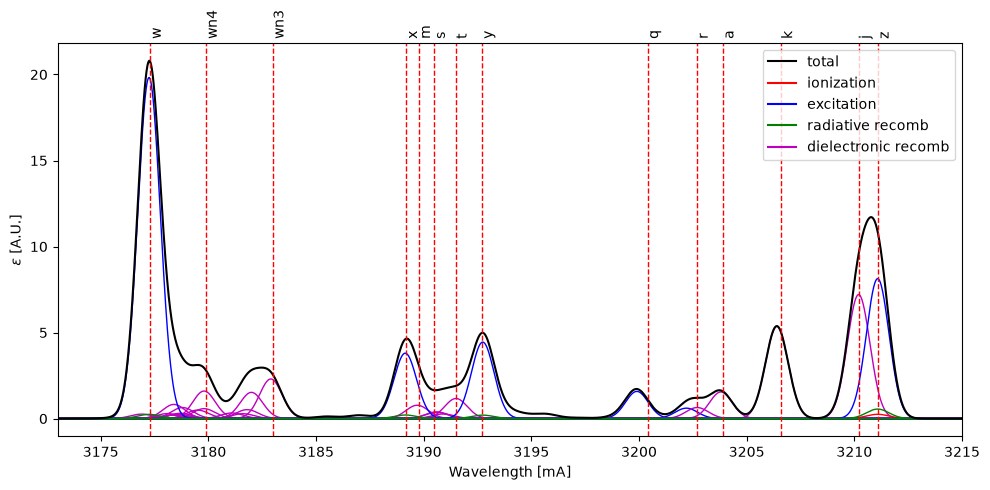

In [3]:
from scipy import constants

Ti_eV = Te
mass_kg = 40.078 * constants.atomic_mass
wave_mA = np.linspace(3173, 3215, 4201)

# Doppler-broadened Gaussian for each row, with area equal to its emissivity
lam0_mA = 1e3 * window['lambda [A]'].to_numpy()[:, None]
sigma_mA = lam0_mA * np.sqrt(Ti_eV * constants.e / mass_kg) / constants.c
profiles = window['emiss'].to_numpy()[:, None] * np.exp(-0.5 * ((wave_mA - lam0_mA) / sigma_mA) ** 2) / (np.sqrt(2 * np.pi) * sigma_mA)
total = profiles.sum(axis=0)

line_labels = {'w': 3177.3, 'wn4': 3179.9, 'wn3': 3183.0, 'x': 3189.2, 'm': 3189.8, 's': 3190.5, 't': 3191.5,
               'y': 3192.7, 'q': 3200.4, 'r': 3202.7, 'a': 3203.9, 'k': 3206.6, 'j': 3210.2, 'z': 3211.1}

processes = {'ioniz': ('ionization', 'r'), 'excit': ('excitation', 'b'),
             'recom': ('radiative recomb', 'g'), 'drsat': ('dielectronic recomb', 'm')}

fig, ax = plt.subplots(figsize=(10, 5))
keep = profiles.max(axis=1) > profiles.max() / 100  # only draw the stronger individual lines
types = window['type'].to_numpy()
for profile, typ in zip(profiles[keep], types[keep]):
    ax.plot(wave_mA, profile, c=processes[typ][1], lw=1)
ax.plot(wave_mA, total, 'k-', lw=1.5, label='total')
for label, color in processes.values():
    ax.plot([], [], c=color, label=label)

for label, position in line_labels.items():
    ax.axvline(position, c='r', ls='--', lw=1)
    ax.text(position, 1.01, label, rotation=90, ha='left', va='bottom',
            transform=ax.get_xaxis_transform())

ax.set_xlim(wave_mA[0], wave_mA[-1])
ax.set_xlabel('Wavelength [mA]')
ax.set_ylabel(r'$\epsilon$ [A.U.]')
ax.legend(loc='upper right')
fig.tight_layout()
plt.show()

In [4]:
import re
from scipy import constants

# Upper and lower level of every row, from the transition table at the end of the file
with open(rf'{sim_dir}\pec#ca17.dat') as f:
    file_lines = f.read().splitlines()
row_format = re.compile(r'^C\s*(\d+)\.\s+[\d.]+\s+(\d+)\(.*\)-\s*(\d+)\(.*\)\s+DRSAT')
levels = pd.DataFrame([m.groups() for m in map(row_format.match, file_lines) if m],
                      columns=['isel', 'upper', 'lower']).astype(int)
configs = dict(m.groups() for m in (re.match(r'^C\s*(\d+)\.\s+((?:\d+[spdfgh]\d\s*)+)$', l) for l in file_lines) if m)
levels['upper_config'] = levels['upper'].astype(str).map(configs).str.strip()
levels['lower_config'] = levels['lower'].astype(str).map(configs).str.strip()

# Gabriel (1972) names for the n=2 satellites; lower levels 1, 2, 3 are 2s, 2p1/2, 2p3/2
GABRIEL = {(10248, 3): 'j', (10247, 2): 'k', (10247, 3): 'l', (10246, 3): 'm', (10246, 2): 'n',
           (10242, 3): 'a', (10242, 2): 'b', (10241, 3): 'c', (10241, 2): 'd', (10245, 3): 'e',
           (10244, 3): 'f', (10244, 2): 'g', (10243, 3): 'h', (10243, 2): 'i', (10000, 3): 'o',
           (10000, 2): 'p', (10004, 1): 'q', (10003, 1): 'r', (10002, 1): 's', (10001, 1): 't',
           (10006, 1): 'u', (10005, 1): 'v'}

pec17 = load_pec(17)
pec17 = pec17[pec17['type'] == 'drsat'].merge(levels, on='isel')

# DR rate: PEC = C * Te^-3/2 * Q_d * exp(-Es/Te), so a straight-line fit gives Q_d and Es
I_H_eV = constants.Rydberg * constants.h * constants.c / constants.e
a0_cm = 100 * constants.physical_constants['Bohr radius'][0]
C = 0.5 * (4 * np.pi * a0_cm ** 2 * I_H_eV) ** 1.5  # cm^3 eV^(3/2), for ground state weight g=1

def fit_Q_d(temps, pec):
    use = (temps >= 100) & (temps <= 30000) & (pec > 1e-35)  # 1e-40 is the file's zero placeholder
    design = np.column_stack([np.ones(use.sum()), -1 / temps[use]])
    coeffs = np.linalg.lstsq(design, np.log(pec[use] * temps[use] ** 1.5), rcond=None)[0]
    return np.exp(coeffs[0]) / C, coeffs[1]

fits = [fit_Q_d(t, p[0]) for t, p in zip(pec17['temp pnts'], pec17['PEC pnts'])]

# Wavelengths of the major He-like lines, from pec#ca18.dat
REFERENCE_mA = {'w': 3177.246, 'x': 3189.145, 'y': 3192.742, 'z': 3211.084}
ref_names = np.array(list(REFERENCE_mA))
ref_mA = np.array(list(REFERENCE_mA.values()))

satellites = pd.DataFrame({
    'label': [GABRIEL.get(key, '') for key in zip(pec17['upper'], pec17['lower'])],
    'isel': pec17['isel'],
    'upper_config': pec17['upper_config'],
    'lower_config': pec17['lower_config'],
    'wavelength_mA': 1e3 * pec17['lambda [A]'],
    'Q_d_per_s': [fit[0] for fit in fits],
    'Es_eV': [fit[1] for fit in fits],
})
nearest_ref = np.abs(satellites['wavelength_mA'].to_numpy()[:, None] - ref_mA).argmin(axis=1)
satellites['nearest_ref'] = ref_names[nearest_ref]
satellites['offset_mA'] = satellites['wavelength_mA'] - ref_mA[nearest_ref]
satellites['offset_from_w_mA'] = satellites['wavelength_mA'] - REFERENCE_mA['w']
satellites = satellites.sort_values('wavelength_mA', ignore_index=True)
satellites[satellites['label'] != '']

,label,isel,upper_config,lower_config,wavelength_mA,Q_d_per_s,Es_eV,nearest_ref,offset_mA,offset_from_w_mA
183,n,1334,1s1 2p2,1s2 2p1,3185.5,5.769168e+12,2770.141250,x,-3.645,8.254
222,m,1378,1s1 2p2,1s2 2p1,3189.7,3.668850e+13,2769.978426,x,0.555,12.454
241,s,1271,1s1 2s1 2p1,1s2 2s1,3190.6,1.759313e+13,2728.147681,x,1.455,13.354
253,t,1270,1s1 2s1 2p1,1s2 2s1,3191.5,5.294552e+13,2730.370474,y,-1.242,14.254
397,b,1331,1s1 2p2,1s2 2p1,3199.6,3.577219e+12,2752.765384,y,6.858,22.354
402,q,1273,1s1 2s1 2p1,1s2 2s1,3200.6,2.058063e+12,2715.421927,y,7.858,23.354
406,r,1272,1s1 2s1 2p1,1s2 2s1,3202.7,2.880057e+13,2713.360167,z,-8.384,25.454
407,a,1374,1s1 2p2,1s2 2p1,3203.8,7.222177e+13,2756.320023,z,-7.284,26.554
408,d,1330,1s1 2p2,1s2 2p1,3203.9,4.396686e+11,2746.875594,z,-7.184,26.654
410,k,1335,1s1 2p2,1s2 2p1,3206.4,2.486276e+14,2748.373465,z,-4.684,29.154


In [5]:
# Same transitions carry different level numbers in the DRSAT and EXCIT/IONIS rows
LINE_LEVELS = {'k': [(10247, 2), (36, 2)], 'j': [(10248, 3), (37, 3)], 'a': [(10242, 3), (39, 3)],
               'm': [(10246, 3), (40, 3)], 's': [(10002, 1), (34, 1)], 't': [(10001, 1), (33, 1)],
               'r': [(10003, 1), (29, 1)], 'q': [(10004, 1), (30, 1)]}
level_to_line = {pair: line for line, pairs in LINE_LEVELS.items() for pair in pairs}

any_row_format = re.compile(r'^C\s*(\d+)\.\s+[\d.]+\s+(\d+)\(.*\)-\s*(\d+)\(.*\)\s+(?:DRSAT|EXCIT|IONIS)')
all_levels = pd.DataFrame([m.groups() for m in map(any_row_format.match, file_lines) if m],
                          columns=['isel', 'upper', 'lower']).astype(int)
all_levels['line'] = [level_to_line.get(key) for key in zip(all_levels['upper'], all_levels['lower'])]
fit_rows = load_pec(17).merge(all_levels.dropna(subset=['line']), on='isel')

def emission_by_process(Te_eV):
    _, fz_Te = aurora.get_frac_abundances(atom, np.array([ne]), np.array([Te_eV]), plot=False)
    out = line_emissivity(fit_rows, ne, Te_eV, fz_Te[0])
    out['line'] = fit_rows['line']
    return out.pivot_table(index='line', columns='type', values='emiss', aggfunc='sum').reindex(list(LINE_LEVELS))

# Share of each line from each process, at the ne and Te set above
emission = emission_by_process(Te)
shares = emission.div(emission.sum(axis=1), axis=0)

# Total emission relative to k, and how far that moves with temperature
scan_Te = [500.0, 750.0, 1000.0, 1500.0, 2000.0, 3000.0]
ratios = pd.DataFrame({T: emission_by_process(T).sum(axis=1) for T in scan_Te})
ratios = ratios / ratios.loc['k']
ratio_to_k = emission.sum(axis=1) / emission.sum(axis=1)['k']

wavelengths = fit_rows.pivot_table(index='line', columns='type', values='lambda [A]').reindex(list(LINE_LEVELS)) * 1e3

# Constraints used in spectral_fitting.ipynb: areas tied to k, positions from DRSAT wavelengths
AREA_TIED = ['j', 'a', 'm', 's']
POSITION_ANCHOR = {'j': 'k', 'a': 'k', 'r': 'k', 'm': 'x', 's': 'x', 't': 'y'}
anchor_mA = {**REFERENCE_mA, 'k': wavelengths.loc['k', 'drsat']}

fit_constraints = {f'ar_{line}': f'{ratio_to_k[line]:.3f} * ar_k' for line in AREA_TIED}
fit_constraints['ar_t'] = 'R_tk * ar_k'
for line, anchor in POSITION_ANCHOR.items():
    offset = wavelengths.loc[line, 'drsat'] - anchor_mA[anchor]
    fit_constraints[f'mu_{line}'] = f'mu_{anchor} {"+" if offset >= 0 else "-"} {abs(offset):.3f}'

fit_inputs = pd.DataFrame({
    'DR_share': shares['drsat'],
    'excit_share': shares['excit'],
    'ioniz_share': shares['ioniz'],
    'ratio_to_k': ratio_to_k,
    'ratio_min': ratios.min(axis=1),
    'ratio_max': ratios.max(axis=1),
    'DRSAT_mA': wavelengths['drsat'],
    'EXCIT_mA': wavelengths['excit'],
    'area_constraint': [fit_constraints.get(f'ar_{line}', 'free') for line in LINE_LEVELS],
    'position_constraint': [fit_constraints.get(f'mu_{line}', 'free') for line in LINE_LEVELS],
})
fit_inputs

,DR_share,excit_share,ioniz_share,ratio_to_k,ratio_min,ratio_max,DRSAT_mA,EXCIT_mA,area_constraint,position_constraint
line,,,,,,,,,,
k,0.999666,0.000334,1.049431e-29,1.000000,1.000000,1.000000,3206.4,3205.8,free,free
j,0.999676,0.000324,7.804890e-30,1.344581,1.344581,1.351687,3210.2,3209.0,1.345 * ar_k,mu_k + 3.800
a,0.998452,0.001548,3.638516e-29,0.288423,0.286227,0.291130,3203.8,3202.9,0.288 * ar_k,mu_k - 2.600
m,0.970511,0.029408,8.107696e-05,0.148363,0.144206,0.154443,3189.7,3188.5,0.148 * ar_k,mu_x + 0.555
s,0.941348,0.058646,5.887501e-06,0.076669,0.076558,0.078058,3190.6,3189.6,0.077 * ar_k,mu_x + 1.455
t,0.926747,0.073253,3.780912e-08,0.233739,0.232656,0.247460,3191.5,3190.6,R_tk * ar_k,mu_y - 1.242
r,0.514108,0.485882,1.037659e-05,0.232470,0.203966,0.377357,3202.7,3202.2,free,mu_k - 3.700
q,0.028284,0.971511,2.057457e-04,0.302294,0.214759,0.696957,3200.6,3199.9,free,free
